# EDA Step1: 読み込み・欠測・分布

**目的**: モデル設計の前に、(1) データが引き継ぎメモの確定値と一致しているか、(2) どの変数にどんな欠測があるか、
(3) 被説明変数・説明変数の分布（歪み・外れ値）がどうなっているかを確認する。ここでは推論はせず、事実の確認のみ。

**データ**: `realestate.v_transactions_with_mesh`（人口統計付き結合ビュー）に、ビューに含まれない
`transactions` の列（延床面積・間口・土地形状・構造・前面道路幅）を `transaction_id` で結合して読み込む。

**根拠（列の意味）**: `area_sqm` は取引CSVの「面積（㎡）」＝土地面積（`scripts/load_transactions.py` の対応表）。
`building_age_years` は「取引時点の年 − 建築年」で、負値は NULL 化されている（同スクリプト）。

In [5]:
# 0. 設定（DB接続は docker-compose.yml の notebook サービスが渡す環境変数を使う）
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

warnings.filterwarnings("ignore", category=FutureWarning)
try:
    import japanize_matplotlib  # noqa: F401  日本語フォント（IPAexGothic同梱）
except ImportError:
    print("[WARN] japanize_matplotlib が未導入です。図の日本語が□になる場合は\n"
          "       %pip install matplotlib japanize-matplotlib  を実行し、カーネルを再起動してください。")
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200, "display.max_columns", 60, "display.float_format", "{:,.3f}".format)

OUT = Path("output/eda_step1")
OUT.mkdir(parents=True, exist_ok=True)

EXPECTED = {"n_total": 7518, "n_chome_exact": 907, "n_oaza_mesh_avg": 6611, "n_growth_notnull": 7495}
CITY = {"14201": "横須賀市", "14210": "三浦市", "14135": "川崎市多摩区", "14136": "川崎市宮前区"}
GROUP = {"横須賀市": "人口減少", "三浦市": "人口減少", "川崎市多摩区": "人口安定・増加", "川崎市宮前区": "人口安定・増加"}
CITY_ORDER = list(CITY.values())
BLUE = "#2a78d6"

engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.environ["DB_USER"], password=os.environ["DB_PASSWORD"],
    host=os.environ.get("DB_HOST", "db"), port=int(os.environ.get("DB_PORT", 5432)),
    database=os.environ["DB_NAME"],
))

In [6]:
# 1. 読み込み: ビュー + transactions の追加列（point_geom は CSV/pandas では不要なので除外）
SQL = """
SELECT
    v.transaction_id, v.municipality_code, v.municipality_name, v.district_name,
    v.matched_oaza_chome_name, v.match_type, v.n_source_points,
    v.trade_price_yen, v.area_sqm, v.building_year, v.building_age_years,
    v.nearest_station_name, v.nearest_station_minutes,
    v.city_planning_zone, v.building_coverage_ratio, v.floor_area_ratio,
    v.transaction_year, v.transaction_quarter,
    v.mesh_code, v.population_2015, v.population_2020,
    v.population_change_rate_15_20, v.aging_rate_2020,
    t.total_floor_area_sqm, t.frontage_m, t.land_shape, t.building_structure, t.front_road_breadth_m
FROM realestate.v_transactions_with_mesh AS v
JOIN realestate.transactions AS t ON t.transaction_id = v.transaction_id
"""
df = pd.read_sql(SQL, engine)

NUM = ["n_source_points", "trade_price_yen", "area_sqm", "building_year", "building_age_years",
       "nearest_station_minutes", "building_coverage_ratio", "floor_area_ratio",
       "transaction_year", "transaction_quarter", "population_2015", "population_2020",
       "population_change_rate_15_20", "aging_rate_2020",
       "total_floor_area_sqm", "frontage_m", "front_road_breadth_m"]
for c in NUM:
    df[c] = pd.to_numeric(df[c], errors="coerce")  # NUMERIC(Decimal)/SMALLINT を float に統一

df["city"] = df["municipality_code"].str.strip().map(CITY)
df["group"] = df["city"].map(GROUP)
df["price_man"] = df["trade_price_yen"] / 1e4
df["log_price"] = np.log(df["trade_price_yen"].where(df["trade_price_yen"] > 0))
df["growth"] = df["population_change_rate_15_20"]

print("shape:", df.shape)
print("city が対象4自治体に対応づかない行:", int(df["city"].isna().sum()))
print("transaction_id 重複:", int(df["transaction_id"].duplicated().sum()), "件")

# 引き継ぎメモの確定値との照合（JOINで行が増減していないかの確認を兼ねる）
chk = {
    "n_total": len(df),
    "n_chome_exact": int((df["match_type"] == "chome_exact").sum()),
    "n_oaza_mesh_avg": int((df["match_type"] == "oaza_mesh_avg").sum()),
    "n_growth_notnull": int(df["growth"].notna().sum()),
}
print("\n[引き継ぎメモとの照合]")
for k, v in chk.items():
    print(f"  {k:18s} 実測={v:>6,}  期待={EXPECTED[k]:>6,}  {'OK' if v == EXPECTED[k] else '<< 不一致 >>'}")
print("  match_type='unmatched':", int((df["match_type"] == "unmatched").sum()), "件（期待=0）")

shape: (7518, 33)
city が対象4自治体に対応づかない行: 0
transaction_id 重複: 0 件

[引き継ぎメモとの照合]
  n_total            実測= 7,518  期待= 7,518  OK
  n_chome_exact      実測=   907  期待=   907  OK
  n_oaza_mesh_avg    実測= 6,611  期待= 6,611  OK
  n_growth_notnull   実測= 7,495  期待= 7,495  OK
  match_type='unmatched': 0 件（期待=0）


In [7]:
# 2. 自治体別の件数と match_type の構成
ct = pd.crosstab(df["city"], df["match_type"]).reindex(CITY_ORDER)
ct["合計"] = ct.sum(axis=1)
ct["chome_exact割合(%)"] = ct.get("chome_exact", 0) / ct["合計"] * 100
print(ct.to_string())

match_type  chome_exact  oaza_mesh_avg    合計  chome_exact割合(%)
city                                                          
横須賀市                293           3578  3871             7.569
三浦市                 117            300   417            28.058
川崎市多摩区              287           1254  1541            18.624
川崎市宮前区              210           1479  1689            12.433


In [8]:
# 3. 欠測: 全体 / 自治体別 / match_type別（欠測がランダムでないか＝偏りの確認）
cols = ["trade_price_yen", "area_sqm", "total_floor_area_sqm", "building_year", "building_age_years",
        "nearest_station_minutes", "frontage_m", "front_road_breadth_m", "land_shape", "building_structure",
        "city_planning_zone", "building_coverage_ratio", "floor_area_ratio", "growth", "aging_rate_2020"]
miss_all = pd.DataFrame({"n_missing": df[cols].isna().sum(), "pct": df[cols].isna().mean() * 100})
print("[全体]\n", miss_all.sort_values("pct", ascending=False).to_string())

miss_city = (df[cols].isna().groupby(df["city"]).mean().T * 100)[CITY_ORDER]
print("\n[自治体別 欠測率 %]\n", miss_city.to_string())

miss_mt = df[cols].isna().groupby(df["match_type"]).mean().T * 100
print("\n[match_type別 欠測率 %]\n", miss_mt.to_string())

# 築年数の整合性: 建築年はあるのに築年数が欠測 = 負の築年数を NULL 化した行
n_neg = int((df["building_age_years"].isna() & df["building_year"].notna()).sum())
print(f"\n[築年数] 建築年ありで築年数が欠測（負値をNULL化）: {n_neg} 件 / 建築年の範囲: "
      f"{df['building_year'].min():.0f}〜{df['building_year'].max():.0f}")

[全体]
                          n_missing    pct
frontage_m                    3614 48.071
land_shape                    3204 42.618
nearest_station_minutes       2019 26.856
front_road_breadth_m           937 12.463
building_age_years             519  6.903
building_year                  344  4.576
building_structure             236  3.139
total_floor_area_sqm           117  1.556
floor_area_ratio                55  0.732
building_coverage_ratio         54  0.718
growth                          23  0.306
area_sqm                        18  0.239
city_planning_zone               2  0.027
aging_rate_2020                  2  0.027
trade_price_yen                  0  0.000

[自治体別 欠測率 %]
 city                      横須賀市    三浦市  川崎市多摩区  川崎市宮前区
trade_price_yen          0.000  0.000   0.000   0.000
area_sqm                 0.155  0.719   0.195   0.355
total_floor_area_sqm     1.731  1.439   1.493   1.243
building_year            6.174  6.954   2.336   2.368
building_age_years       8.473  6.954

In [9]:
# 4. 人口増減率が欠測の行（メモ上は23件＝メッシュ秘匿による正当な欠測のはず）
na_g = df[df["growth"].isna()]
print(f"growth 欠測 {len(na_g)} 件")
print(na_g.groupby(["city", "match_type"]).size().to_frame("n").to_string())
print("\n大字名（上位）:")
print(na_g.groupby(["city", "district_name"]).size().sort_values(ascending=False).head(10).to_string())

growth 欠測 23 件
                   n
city match_type     
三浦市  chome_exact  21
横須賀市 chome_exact   2

大字名（上位）:
city  district_name
三浦市   晴海町              19
      向ヶ崎町              2
横須賀市  夏島町               1
      神明町               1


In [10]:
# 5. 要約統計（歪度・外れ値の件数）。歪度が大きい変数は対数化の候補
num_cols = ["price_man", "log_price", "area_sqm", "total_floor_area_sqm", "building_age_years",
            "nearest_station_minutes", "frontage_m", "front_road_breadth_m",
            "growth", "aging_rate_2020", "n_source_points"]


def summarize(d: pd.DataFrame, cols) -> pd.DataFrame:
    rows = []
    for c in cols:
        x = d[c].dropna()
        q1, q3 = x.quantile([.25, .75])
        iqr = q3 - q1
        rows.append({"var": c, "n": len(x), "mean": x.mean(), "sd": x.std(), "min": x.min(),
                     "p1": x.quantile(.01), "p50": x.median(), "p99": x.quantile(.99), "max": x.max(),
                     "skew": stats.skew(x), "n_out_1.5IQR": int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()),
                     "n_out_3IQR": int(((x < q1 - 3 * iqr) | (x > q3 + 3 * iqr)).sum())})
    return pd.DataFrame(rows).set_index("var")


desc = summarize(df, num_cols)
print(desc.to_string())
print(f"\n価格の歪度: 元={stats.skew(df['price_man'].dropna()):.2f} → 対数={stats.skew(df['log_price'].dropna()):.2f}")
print("価格<=0:", int((df["trade_price_yen"] <= 0).sum()), "件 / 面積<=0:", int((df["area_sqm"] <= 0).sum()), "件")

                            n      mean        sd    min      p1       p50        p99         max   skew  n_out_1.5IQR  n_out_3IQR
var                                                                                                                               
price_man                7518 4,232.925 7,833.674  0.400 191.700 3,400.000 23,000.000 270,000.000 17.806           369         176
log_price                7518    17.179     0.897  8.294  14.466    17.342     19.254      21.717 -1.085           638         101
area_sqm                 7500   154.293   129.614 35.000  50.000   125.000    740.100   1,800.000  5.687           484         249
total_floor_area_sqm     7401   117.136   108.070 10.000  50.000   100.000    500.000   1,900.000  9.345           994         500
building_age_years       6999    18.941    18.624  0.000   0.000    15.000     61.000      76.000  0.571             0           0
nearest_station_minutes  5499    13.705     6.340  0.000   3.000    13.000     28.0

In [11]:
# 6. カテゴリ変数の内訳（NaNも表示）
for c in ["land_shape", "building_structure", "city_planning_zone"]:
    print(f"\n[{c}]")
    print(df[c].value_counts(dropna=False).head(12).to_string())


[land_shape]
land_shape
None     3204
ほぼ長方形    1285
長方形       944
不整形       560
ほぼ台形      475
袋地等       412
ほぼ整形      233
台形        199
ほぼ正方形     180
正方形        26

[building_structure]
building_structure
木造             6556
軽量鉄骨造           374
None            236
RC              180
鉄骨造             143
RC、木造            12
SRC               6
鉄骨造、木造            4
ブロック造             4
RC、木造、ブロック造       1
木造、軽量鉄骨造          1
RC、軽量鉄骨造          1

[city_planning_zone]
city_planning_zone
1低住専    2696
1中住専    2680
1種住居    1031
近隣商業     234
準住居      196
2中住専     187
準工業      132
2種住居     126
商業        76
調整区域      58
工業        49
2低住専      40


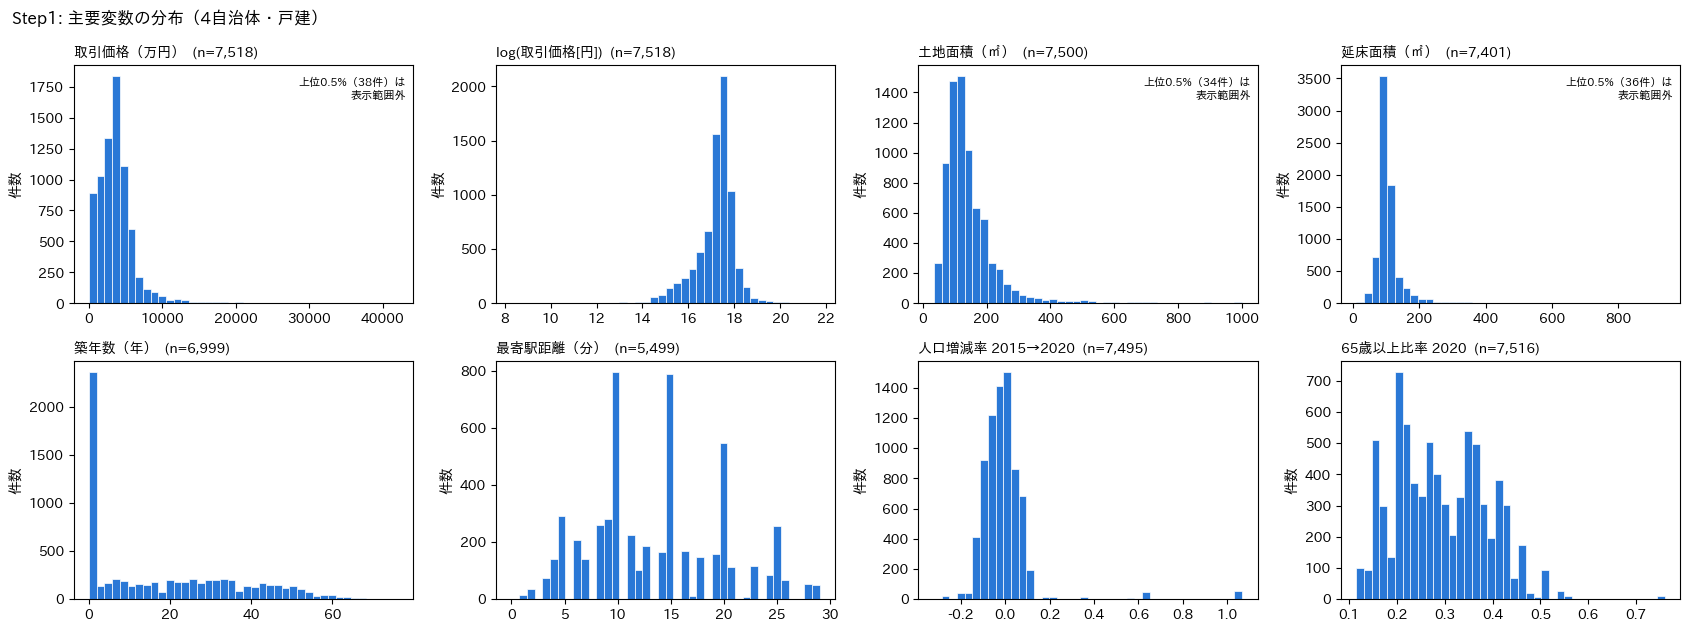

In [12]:
# 7. 分布（ヒストグラム）。右裾が長い変数は上位0.5%を表示範囲外にして件数を注記
panels = [("price_man", "取引価格（万円）", True), ("log_price", "log(取引価格[円])", False),
          ("area_sqm", "土地面積（㎡）", True), ("total_floor_area_sqm", "延床面積（㎡）", True),
          ("building_age_years", "築年数（年）", False), ("nearest_station_minutes", "最寄駅距離（分）", True),
          ("growth", "人口増減率 2015→2020", False), ("aging_rate_2020", "65歳以上比率 2020", False)]
fig, axes = plt.subplots(2, 4, figsize=(17, 6.4))
for ax, (c, lab, clip) in zip(axes.ravel(), panels):
    x = df[c].dropna()
    hi = x.quantile(.995) if clip else x.max()
    n_cut = int((x > hi).sum())
    ax.hist(x[x <= hi], bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(f"{lab}  (n={len(x):,})", fontsize=10, loc="left")
    ax.set_ylabel("件数")
    if n_cut:
        ax.text(0.98, 0.95, f"上位0.5%（{n_cut}件）は\n表示範囲外", transform=ax.transAxes, ha="right", va="top", fontsize=8)
fig.suptitle("Step1: 主要変数の分布（4自治体・戸建）", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT / "1_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# 8. 自治体別の価格（万円）と取引年別の件数（期間の偏りの確認）
tab = df.groupby("city")["price_man"].describe(percentiles=[.25, .5, .75]).reindex(CITY_ORDER)
print("[自治体別 取引価格（万円）]\n", tab.to_string())
print("\n[取引年 × 自治体 件数]")
print(pd.crosstab(df["transaction_year"], df["city"])[CITY_ORDER].to_string())

[自治体別 取引価格（万円）]
            count      mean        std    min       25%       50%       75%         max
city                                                                                  
横須賀市   3,871.000 3,042.313  6,095.656  0.400 1,400.000 2,700.000 3,600.000 270,000.000
三浦市      417.000 2,375.336  5,277.175 10.000   830.000 1,700.000 2,900.000 100,000.000
川崎市多摩区 1,541.000 5,835.681  7,949.661 35.000 3,700.000 4,700.000 5,600.000 180,000.000
川崎市宮前区 1,689.000 5,957.987 10,683.798 50.000 3,700.000 4,500.000 5,700.000 260,000.000

[取引年 × 自治体 件数]
city              横須賀市  三浦市  川崎市多摩区  川崎市宮前区
transaction_year                           
2021               780   88     333     387
2022               612   77     218     297
2023               636   67     276     255
2024               593   76     255     243
2025              1046   87     396     414
2026               204   22      63      93


In [14]:
import eda_step2_preprocessing as pp
import statsmodels.formula.api as smf

# 1. 既存の df に備考・用途を結合
df_with_extra = pp.attach_extra_columns(df, engine)

# 2. 前処理を一括実行
df_clean, filter_log = pp.preprocess(df_with_extra)

# 3. 主モデル（中古のみ）の回帰を実行
df_used = pp.get_sample(df_clean, "used")
formula_used = pp.build_formula("used")

res_used = smf.ols(formula_used, data=df_used).fit(
    cov_type="cluster",
    cov_kwds={"groups": pd.factorize(df_used["cluster_oaza"])[0]},
)
print(res_used.summary())

[attach_extra_columns] use_purpose 非NULL 4,155 / remarks 非NULL 240 / 全 7,518 件
[前処理] 入力 7,518 件
    - 備考『関係者間取引』 /関係者/ に該当: 10 件（重複含む）
    - 備考『持分取引』 /持分/ に該当: 0 件（重複含む）
    - 備考『競売・調停等』 /競売|調停/ に該当: 75 件（重複含む）
    - 備考『隣地の購入』 /隣地/ に該当: 9 件（重複含む）
    - 備考『権利・負担付き』 /他の権利|負担付/ に該当: 0 件（重複含む）
  [1. 備考(remarks)除外] 除外 94 件（入力の 1.25%） → 残り 7,424 件
    （参考）除外後に残っている備考の上位: {'私道を含む取引': 146}
    （参考）use_purpose の内訳: {'NULL': 3357, '住宅': 3330, '共同住宅': 454, '住宅、駐車場': 48, '住宅、店舗': 47, '店舗': 33, '共同住宅、店舗': 25, 'その他': 22}
    - 用途が『住宅』以外（非NULL）: 737 件 / 用途NULL: 3,357 件（方針: keep）
  [2. 用途(use_purpose)除外] 除外 737 件（入力の 9.80%） → 残り 6,687 件
    - ln_price が欠測: 0 件
    - ln_land_area が欠測: 2 件
    - ln_floor_area が欠測: 83 件
    - growth が欠測: 21 件
    - 取引年/四半期 が欠測: 0 件
    - うち 価格/土地面積/延床面積 が 0 以下: 0 件
  [3. 必須変数の欠測除外] 除外 105 件（入力の 1.40%） → 残り 6,582 件
    - 価格が 100,000 円未満の行（除外）: [4000.0] 円
  [3b. 価格下限(<10万円)除外] 除外 1 件（入力の 0.01%） → 残り 6,581 件
    - 築年数の整合性: ビュー値と再計算値の不一致 0 件（0 が正常）
    - 建築年が取引年より後 → 築0に丸めた行

In [15]:
df = pp.attach_extra_columns(df, engine)    # remarks / use_purpose を SELECT で追加（再ロードなし）
df_clean, filter_log = pp.preprocess(df)    # 除外ログを標準出力し、回帰用 df_clean を返す

import pandas as pd, statsmodels.formula.api as smf
d = pp.get_sample(df_clean, "used")         # 主分析: 中古のみ
res = smf.ols(pp.build_formula("used"), data=d).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(d["cluster_oaza"])[0]})

[attach_extra_columns] use_purpose 非NULL 4,155 / remarks 非NULL 240 / 全 7,518 件
[前処理] 入力 7,518 件
    - 備考『関係者間取引』 /関係者/ に該当: 10 件（重複含む）
    - 備考『持分取引』 /持分/ に該当: 0 件（重複含む）
    - 備考『競売・調停等』 /競売|調停/ に該当: 75 件（重複含む）
    - 備考『隣地の購入』 /隣地/ に該当: 9 件（重複含む）
    - 備考『権利・負担付き』 /他の権利|負担付/ に該当: 0 件（重複含む）
  [1. 備考(remarks)除外] 除外 94 件（入力の 1.25%） → 残り 7,424 件
    （参考）除外後に残っている備考の上位: {'私道を含む取引': 146}
    （参考）use_purpose の内訳: {'NULL': 3357, '住宅': 3330, '共同住宅': 454, '住宅、駐車場': 48, '住宅、店舗': 47, '店舗': 33, '共同住宅、店舗': 25, 'その他': 22}
    - 用途が『住宅』以外（非NULL）: 737 件 / 用途NULL: 3,357 件（方針: keep）
  [2. 用途(use_purpose)除外] 除外 737 件（入力の 9.80%） → 残り 6,687 件
    - ln_price が欠測: 0 件
    - ln_land_area が欠測: 2 件
    - ln_floor_area が欠測: 83 件
    - growth が欠測: 21 件
    - 取引年/四半期 が欠測: 0 件
    - うち 価格/土地面積/延床面積 が 0 以下: 0 件
  [3. 必須変数の欠測除外] 除外 105 件（入力の 1.40%） → 残り 6,582 件
    - 価格が 100,000 円未満の行（除外）: [4000.0] 円
  [3b. 価格下限(<10万円)除外] 除外 1 件（入力の 0.01%） → 残り 6,581 件
    - 築年数の整合性: ビュー値と再計算値の不一致 0 件（0 が正常）
    - 建築年が取引年より後 → 築0に丸めた行

In [16]:
m = df_clean.merge(df[["transaction_id", "use_purpose"]], on="transaction_id", how="left")
m["use_null"] = m["use_purpose"].isna()
for k in ["new_build", "city", "transaction_year", "match_type"]:
  print(k, m.groupby(k, observed=True)["use_null"].mean().round(3).to_dict())
print(m.groupby("use_null")["ln_floor_area"].describe(percentiles=[.5, .9, .99]).round(2))
print(df_clean["trade_price_yen"].div(1e4).describe(percentiles=[.001, .01, .99, .999]).round(0))

new_build {0: 0.548, 1: 0.396}
city {'横須賀市': 0.523, '三浦市': 0.401, '川崎市多摩区': 0.444, '川崎市宮前区': 0.518}
transaction_year {2021: 0.395, 2022: 0.467, 2023: 0.427, 2024: 0.44, 2025: 0.633, 2026: 0.756}


match_type {'chome_exact': 0.479, 'oaza_mesh_avg': 0.504}
             count  mean   std   min   50%   90%   99%   max
use_null                                                    
False    3,286.000 4.560 0.260 2.300 4.610 4.830 5.280 7.380
True     3,295.000 4.610 0.230 3.220 4.610 4.870 5.270 6.330
count     6,581.000
mean      3,533.000
std       4,053.000
min          10.000
0.1%         29.000
1%          200.000
50%       3,400.000
99%      10,000.000
99.9%    23,840.000
max     270,000.000
Name: trade_price_yen, dtype: float64


In [17]:
import importlib, eda_step2_preprocessing as pp, eda_step3_diagnostics as dg
importlib.reload(pp); importlib.reload(dg)
df = pp.attach_extra_columns(df, engine)
df_clean, filter_log = pp.preprocess(df)
coef_table = dg.run_all(df, df_clean)

[attach_extra_columns] use_purpose 非NULL 4,155 / remarks 非NULL 240 / 全 7,518 件
[前処理] 入力 7,518 件
    - 備考『関係者間取引』 /関係者/ に該当: 10 件（重複含む）
    - 備考『持分取引』 /持分/ に該当: 0 件（重複含む）
    - 備考『競売・調停等』 /競売|調停/ に該当: 75 件（重複含む）
    - 備考『隣地の購入』 /隣地/ に該当: 9 件（重複含む）
    - 備考『権利・負担付き』 /他の権利|負担付/ に該当: 0 件（重複含む）
  [1. 備考(remarks)除外] 除外 94 件（入力の 1.25%） → 残り 7,424 件
    （参考）除外後に残っている備考の上位: {'私道を含む取引': 146}
    （参考）use_purpose の内訳: {'NULL': 3357, '住宅': 3330, '共同住宅': 454, '住宅、駐車場': 48, '住宅、店舗': 47, '店舗': 33, '共同住宅、店舗': 25, 'その他': 22}
    - 用途が『住宅』以外（非NULL）: 737 件 / 用途NULL: 3,357 件（方針: keep）
  [2. 用途(use_purpose)除外] 除外 737 件（入力の 9.80%） → 残り 6,687 件
    - ln_price が欠測: 0 件
    - ln_land_area が欠測: 2 件
    - ln_floor_area が欠測: 83 件
    - growth が欠測: 21 件
    - 取引年/四半期 が欠測: 0 件
    - うち 価格/土地面積/延床面積 が 0 以下: 0 件
  [3. 必須変数の欠測除外] 除外 105 件（入力の 1.40%） → 残り 6,582 件
    - 価格が 100,000 円未満の行（除外）: [4000.0] 円
  [3b. 価格下限(<10万円)除外] 除外 1 件（入力の 0.01%） → 残り 6,581 件
    - 築年数の整合性: ビュー値と再計算値の不一致 0 件（0 が正常）
    - 建築年が取引年より後 → 築0に丸めた行

In [18]:
import importlib, eda_step2_preprocessing as pp, eda_step3_diagnostics as dg
importlib.reload(pp); importlib.reload(dg)
df = pp.attach_extra_columns(df, engine)
df_clean, filter_log = pp.preprocess(df)
summary = dg.run_all(df, df_clean)     # 戻り値が統合比較表（DataFrame）
summary

[attach_extra_columns] use_purpose 非NULL 4,155 / remarks 非NULL 240 / 全 7,518 件
[前処理] 入力 7,518 件
    - 備考『関係者間取引』 /関係者/ に該当: 10 件（重複含む）
    - 備考『持分取引』 /持分/ に該当: 0 件（重複含む）
    - 備考『競売・調停等』 /競売|調停/ に該当: 75 件（重複含む）
    - 備考『隣地の購入』 /隣地/ に該当: 9 件（重複含む）
    - 備考『権利・負担付き』 /他の権利|負担付/ に該当: 0 件（重複含む）
  [1. 備考(remarks)除外] 除外 94 件（入力の 1.25%） → 残り 7,424 件
    （参考）除外後に残っている備考の上位: {'私道を含む取引': 146}
    （参考）use_purpose の内訳: {'NULL': 3357, '住宅': 3330, '共同住宅': 454, '住宅、駐車場': 48, '住宅、店舗': 47, '店舗': 33, '共同住宅、店舗': 25, 'その他': 22}
    - 用途が『住宅』以外（非NULL）: 737 件 / 用途NULL: 3,357 件（方針: keep）
  [2. 用途(use_purpose)除外] 除外 737 件（入力の 9.80%） → 残り 6,687 件
    - ln_price が欠測: 0 件
    - ln_land_area が欠測: 2 件
    - ln_floor_area が欠測: 83 件
    - growth が欠測: 21 件
    - 取引年/四半期 が欠測: 0 件
    - うち 価格/土地面積/延床面積 が 0 以下: 0 件
  [3. 必須変数の欠測除外] 除外 105 件（入力の 1.40%） → 残り 6,582 件
    - 価格が 100,000 円未満の行（除外）: [4000.0] 円
  [3b. 価格下限(<10万円)除外] 除外 1 件（入力の 0.01%） → 残り 6,581 件
    - 築年数の整合性: ビュー値と再計算値の不一致 0 件（0 が正常）
    - 建築年が取引年より後 → 築0に丸めた行

,Spec,Coef,SE,95% CI,p-value,+0.1あたり変化率,n,clusters
0,R0 主分析,+0.3628,0.1070,"[+0.151, +0.574]",0.0009,+3.7%,"4,535",157
1,R1 全標本+新築交互作用（中古の傾き）,+0.4180,0.1232,"[+0.175, +0.661]",0.0009,+4.3%,"6,581",157
2,R1 全標本+新築交互作用（新築との差）,-0.6201,0.2938,"[-1.200, -0.040]",0.0364,-6.0%,"6,581",157
3,R1 全標本+新築交互作用（新築の傾き）,-0.2022,0.2187,"[-0.634, +0.230]",0.3566,-2.0%,"6,581",157
4,R2 用途NULLを除外,+0.3611,0.1647,"[+0.036, +0.686]",0.0299,+3.7%,"2,051",155
5,R3 growth極端値を除外,+0.6236,0.3671,"[-0.102, +1.349]",0.0914,+6.4%,"4,469",155
6,R3b ln(人口比)・極端値除外,+0.8005,0.4166,"[-0.022, +1.623]",0.0565,+8.3%,"4,469",155
7,R4 ln(人口比),+0.6190,0.1881,"[+0.247, +0.991]",0.0012,+6.4%,"4,535",157
8,R5 価格p1〜p99のみ,+0.3495,0.0889,"[+0.174, +0.525]",0.0001,+3.6%,"4,430",157
9,R6 chome_exact のみ,+0.2818,0.5433,"[-0.815, +1.378]",0.6067,+2.9%,528,43
